# Filbin 2018 — 03 · Signatures (Gate 2 & Gate 3)

Read the embryonic-module **geography** off the manifold. **Gate 2** asks whether the Gast/pSom
pattern appears with Crest as a terminal readout. **Gate 3** (branching-only) asks whether the
convergence hub shows mutual Gast↔pSom cross-repression. Signature UMAPs show **raw** per-cell
scores (smoothing is for reading geography, not for the deliverable).

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout, consistent orientation
print('cells:', adata.shape[0], '| modules present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = pd.read_csv(os.path.join(pth_feat, src+'.csv')).hsapiens.dropna().drop_duplicates()
    print(f'{lab}: {g.isin(adata.var_names).sum()}/{g.size} genes present')

cells: 2259 | modules present: ['Gast', 'pSom', 'Crest']
Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 102/104 genes present


### Gate 2 — module geography
Smoothed spatial correlations + gradients along pseudotime; the Crest-high decile pseudotime tells
us whether Crest is terminal. Raw global means are the log-row values.

In [4]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  {s}: rho = {spearmanr(t, adata.obs[s]).statistic:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'\nNeural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('raw global module means:', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})
print('\nGast/pSom share one gradient (co-vary, both oppose Crest); Crest is a terminal readout at')
print('the high-pseudotime end (not enriched on a Gast arm -> no inversion flag).')
print('GATE 2: embryonic pattern present, non-branching -> GO')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.64
  Crest_sm vs Gast_sm: r = -0.89
  Crest_sm vs pSom_sm: r = -0.61

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.768
  pSom_sm: rho = -0.248
  Crest_sm: rho = +0.860

Neural-crest-high decile mean pseudotime = 0.98 (terminal if ~1)
raw global module means: {'Gast': 0.018, 'pSom': 0.226, 'Crest': 0.1}

Gast/pSom share one gradient (co-vary, both oppose Crest); Crest is a terminal readout at
the high-pseudotime end (not enriched on a Gast arm -> no inversion flag).
GATE 2: embryonic pattern present, non-branching -> GO


### Gate 3 (branching-only) is NA — the embryonic axis does not bifurcate
Geometry is non-branching (02: Gast/pSom co-vary +0.64, both oppose Crest; single collapsed axis),
so Gate 3 — the *branching-only* hub cross-repression test — is **NA**. Two robust checks confirm
this is not a missed bifurcation. **(1) Neither arm is Gast-dominant.** A Puram bifurcation requires a
Gast-leaning arm opposite a pSom-leaning arm; here Gast has almost no dynamic range and *both*
differentiated glial arms (AC-like, OC-like) stay pSom-dominant. **(2) A joint-score-selected "hub"
r is collider-biased** — selecting the Gast/pSom-high cells forces a negative per-gene r even under
statistical independence (02 null ≈ −0.74), so a negative hub r read that way is an artifact, not
cross-repression. The role-based convergence region co-varies (smoothed +0.64).

In [5]:
# (1) neither glial arm is Gast-dominant (both pSom-leaning) -> single collapsed axis, not a Y of modules
print('arm module identity (data-driven; AC-like/OC-like lobes vs global):')
print('  global means:', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})
for lb,ci in [('AC-like (lobe 6)','6'),('OC-like (lobe 8)','8')]:
    m=(adata.obs['lobe']==ci).values
    if m.sum()>10:
        print(f'  {lb}: n={m.sum():3d} Gast={adata.obs.Gast[m].mean():+.3f} '
              f'pSom={adata.obs.pSom[m].mean():+.3f} Crest={adata.obs.Crest[m].mean():+.3f}')
print('  -> both arms pSom>Gast; no Gast arm; Gast dynamic range ~0. Not a Puram bifurcation.')

# (2) collider control: selecting joint-high cells forces negativity even under independence
rng=np.random.default_rng(0); G=adata.obs['Gast'].values; n9=int(0.09*adata.n_obs); pcs=[]
for _ in range(200):
    P=rng.permutation(adata.obs['pSom'].values); sel=np.argsort(G+P)[-n9:]
    pcs.append(np.corrcoef(G[sel],P[sel])[0,1])
joint=adata.obs['Gast'].values+adata.obs['pSom'].values; sh=np.argsort(joint)[-n9:]
print(f'\ncollider control: joint-high(top9%) per-cell Gast~pSom = '
      f'{np.corrcoef(adata.obs.Gast.values[sh],adata.obs.pSom.values[sh])[0,1]:+.3f} '
      f'| independence null = {np.mean(pcs):+.3f} +/- {np.std(pcs):.3f}')
print('  -> a negative "hub r" from joint-score selection is a selection artifact, not biology.')
print('\nGATE 3: NA (non-branching; branching-only cross-repression test not applicable)')

arm module identity (data-driven; AC-like/OC-like lobes vs global):
  global means: {'Gast': 0.018, 'pSom': 0.226, 'Crest': 0.1}
  AC-like (lobe 6): n=341 Gast=+0.047 pSom=+0.212 Crest=+0.042
  OC-like (lobe 8): n= 94 Gast=+0.029 pSom=+0.173 Crest=+0.050
  -> both arms pSom>Gast; no Gast arm; Gast dynamic range ~0. Not a Puram bifurcation.

collider control: joint-high(top9%) per-cell Gast~pSom = -0.531 | independence null = -0.735 +/- 0.040
  -> a negative "hub r" from joint-score selection is a selection artifact, not biology.

GATE 3: NA (non-branching; branching-only cross-repression test not applicable)


### Deliverables — signature UMAPs (RAW scores) + external colorbars

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


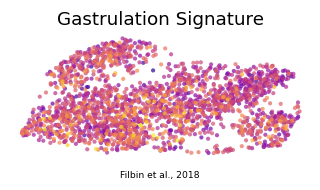

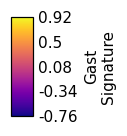

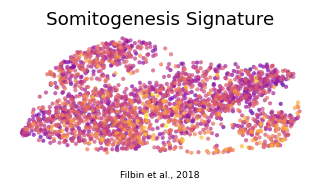

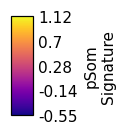

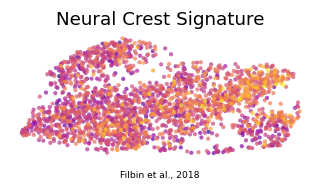

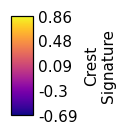

In [6]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.13, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (2259, 21224)
